In [1]:
import os
os.environ['PATH'] = 'C:\\Users\\nabod\\AppData\\Roaming\\Python\\Python39\\Scripts' + os.pathsep + os.environ['PATH']

In [2]:
!kadi-apy config create

Config file already exists at 'C:\Users\nabod\.kadiconfig'. Nothing to create.


In [3]:
from kadi_apy import KadiManager

In [4]:
manager = KadiManager(host="https://kadi4mat.iam-cms.kit.edu/", token="pat_2b1dbbb54381b91093317e813109bcdabb182395a668e07f")

In [5]:
# Retrieve an existing record by its ID.
record = manager.record(id=17917)

In [6]:
record

In [7]:
record= manager.record(identifier = "pfm_multiplastic-15-150")

In [9]:
record

In [9]:
record.check_metadatum("Process Parameters")

True

In [10]:
b= record.get_metadatum("Process Parameters")

In [21]:
record.get_filelist()

<Response [200]>

In [11]:
print (b)

{'key': 'Process Parameters', 'type': 'dict', 'value': [{'key': 'Power', 'type': 'float', 'unit': 'Watt', 'value': 15.0}, {'key': 'Scan Speed', 'type': 'float', 'unit': 'mm/s', 'value': 150.0}]}


In [13]:
import pandas as pd

In [14]:
pd.DataFrame.from_dict(b)

,key,type,value
0,Process Parameters,dict,"{'key': 'Power', 'type': 'float', 'unit': 'Wat..."
1,Process Parameters,dict,"{'key': 'Scan Speed', 'type': 'float', 'unit':..."


In [33]:
import pandas as pd

data = {
    'key': 'Process Parameters',
    'type': 'dict',
    'value': [
        {'key': 'Power', 'type': 'float', 'unit': 'Watt', 'value': 15.0},
        {'key': 'Scan Speed', 'type': 'float', 'unit': 'mm/s', 'value': 150.0}
    ]
}

# Extracting values for 'Power' and 'Scan Speed' with their units
power = data['value'][0]['value']
power_unit = data['value'][0]['unit']
scan_speed = data['value'][1]['value']
scan_speed_unit = data['value'][1]['unit']

# Creating a DataFrame
df = pd.DataFrame({'Power': [power], 'Power Unit': [power_unit],
                   'Scan Speed': [scan_speed], 'Scan Speed Unit': [scan_speed_unit]})

print(df)


   Power Power Unit  Scan Speed Scan Speed Unit
0   15.0       Watt       150.0            mm/s


In [15]:
record.get_tags()

['multilayer plasticity', 'phase-field', 'sls']

In [30]:
record.check_tag('sls')

True

In [24]:
record.get_number_files()

0

In [25]:
record.get_groups()

<Response [200]>

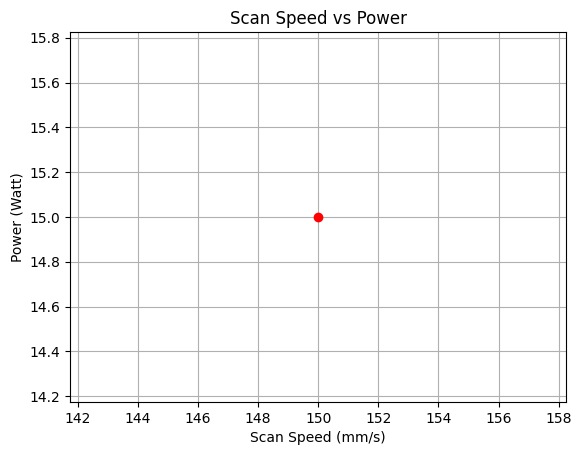

In [13]:
import matplotlib.pyplot as plt

data = {
    'key': 'Process Parameters',
    'type': 'dict',
    'value': [
        {'key': 'Power', 'type': 'float', 'unit': 'Watt', 'value': 15.0},
        {'key': 'Scan Speed', 'type': 'float', 'unit': 'mm/s', 'value': 150.0}
    ]
}

# Extracting the values for scan speed and power
scan_speed = data['value'][1]['value']
power = data['value'][0]['value']

# Plotting the data
plt.plot(scan_speed, power, 'ro')
plt.xlabel('Scan Speed (mm/s)')
plt.ylabel('Power (Watt)')
plt.title('Scan Speed vs Power')
plt.grid(True)
plt.show()


In [15]:
collection= manager.collection(identifier = "collect20220322_mnpssls")


In [16]:
collection

In [17]:
collection.get_users()

<Response [200]>

In [19]:
collection.get_tags()

[]

In [27]:
record.export(path = "pfm_multiplastic-15-150.json", export_type = "json") 

<Response [200]>

In [23]:
record= manager.record(identifier = "pfm_multiplastic-20-100")

In [26]:
record.export(path = "pfm_multiplastic-20-100.json", export_type = "json") 

<Response [200]>

In [31]:
import pandas as pd
import json

metadata_file = 'pfm_multiplastic-15-150.json'

# Read the metadata from the file
with open(metadata_file, 'r') as f:
    metadata = json.load(f)

# Extract the 'Power' and 'Scan Speed' values
values = []
for item in metadata['extras'][0]['value']:
    if item['key'] in ['Power', 'Scan Speed']:
        values.append(item['value'])

# Create a dataframe from the extracted values
df = pd.DataFrame({'Value': values})

print(df)



   Value
0   20.0
1  100.0


In [32]:
import pandas as pd
import json

metadata_file = 'pfm_multiplastic-15-150.json'

# Read the metadata from the file
with open(metadata_file, 'r') as f:
    metadata = json.load(f)

# Extract the 'Power' and 'Scan Speed' values
data = []
for item in metadata['extras'][0]['value']:
    if item['key'] in ['Power', 'Scan Speed']:
        data.append({
            'Item': item['key'],
            'Value': item['value'],
            'Unit': item['unit']
        })

# Create a dataframe from the extracted values
df = pd.DataFrame(data)

print(df)


         Item  Value  Unit
0       Power   20.0  Watt
1  Scan Speed  100.0  mm/s
